In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

In [2]:
data = pd.read_csv('processed_train.csv')
data.head()

,EngineVersion,AppVersion,AvSigVersion,RtpStateBitfield,IsSxsPassiveMode,AVProductStatesIdentifier,AVProductsInstalled,AVProductsEnabled,HasTpm,CountryIdentifier,...,Platform_windows8,Processor_x64,Processor_x86,Census_DeviceFamily_Windows.Server,Census_OSArchitecture_arm64,Census_OSArchitecture_x86,Census_GenuineStateName_IS_GENUINE,Census_GenuineStateName_OFFLINE,Census_GenuineStateName_UNKNOWN,HasDetections
0,0.552153,0.530941,0.587952,7.0,0,53447.0,1.0,1.0,1,29,...,0,1,0,0,0,0,1,0,0,0
1,0.448751,0.528931,0.484434,7.0,0,53447.0,1.0,1.0,1,93,...,0,1,0,0,0,0,0,1,0,0
2,0.552153,0.530941,0.557522,7.0,0,53447.0,1.0,1.0,1,86,...,0,1,0,0,0,0,1,0,0,0
3,0.552153,0.530941,0.482759,7.0,0,53447.0,1.0,1.0,1,97,...,0,1,0,0,0,0,1,0,0,0
4,0.493175,0.530941,0.505721,7.0,0,53447.0,1.0,1.0,1,164,...,0,1,0,0,0,0,1,0,0,0


Разобьем выборку на тест и трейн

In [3]:
from sklearn.model_selection import train_test_split

X = data.drop('HasDetections', axis=1)
y = data['HasDetections']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size=0.2,
                                                    random_state=33)

Обучите LogReg и SVM с помощью классов `LogisticRegression` и `LinearSVC`. Добавьте шаг стандартизации данных в пайплайны. Для разнообразия, возьмем `MinMaxScaler`. Пайплайны запишем в переменные `pipe_lr` и `pipe_svm` соответственно!

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.preprocessing import MinMaxScaler

pipe_lr = Pipeline([
    ('scaler', MinMaxScaler()),
    ('classifier', LogisticRegression())
])

pipe_svm = Pipeline([
    ('scaler', MinMaxScaler()),
    ('classifier', LinearSVC())
])



In [5]:
### Обучаем модели на трейне

pipe_lr.fit(X_train, y_train)
pipe_svm.fit(X_train, y_train)

print(round(pipe_lr.score(X_test, y_test), 3))
print(round(pipe_svm.score(X_test, y_test), 3))

0.843
0.84


Постройте ROC для обеих моделей, посчитайте AUC . Конечно же, обучение проводите на трейне, а замеры - на тесте.

Заметьте! Классическая реализация `SVM`, как и в лекциях, не дает никакой оценки вероятности. Чтобы трансформировать выходы в вероятности, на практике мы использовали функцию-сигмоиду. Здесь предлагаем Вам трансформировать выходы `decision_function` в вероятности пропорциональным способом.

Например, вы обучили `SVM`, и на тестовых данных модель выдала следующие выходы `decision_function`:

(-10, -5, 0, +2, +10, +15)

Для каждого числа необходимо сделать преобразование в выражение вида `P(y = +1 | x)`.

С одной стороны, отрицательный знак числа будет сигнализировать нам о том, что `P(y = +1 | x) < 0.5`.

Тогда положительный о том, что `P(y = +1 | x) > 0.5`. 

С другой стороны, для тех объектов, в которых модель уверена больше всего, положим краевые вероятности. Для примера выше:

`P(y = +1 | -10) = 0`, `P(y = +1 | +15) = 1`. Для всех промежуточных объектов применим пропорциональное преобразование. Например:

$$
P(y = +1 | -5) = \frac{|-5-(-10)|}{|-10|} \cdot 0.5
$$

$$
P(y = +1 | +2) = \frac{|+2|}{|+15|} \cdot 0.5 + 0.5
$$
Таким образом мы можем перевести выходы SVM в отрезок [0;1] и попробовать интерпретировать новые числа как вероятности, чтобы изобразить калибровочную кривую. При таком преобразовании пропорции внутри первоначально отрицательных и внутри положительных чисел сохраняются.

In [6]:
from sklearn.metrics import roc_curve
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import auc 

0.689


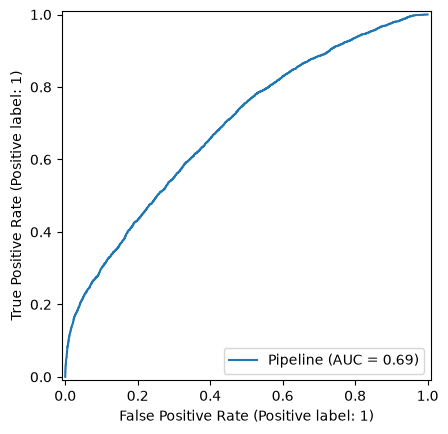

In [7]:
### С изображением рок-кривой для ЛогРега не будет проблем:

y_score = pipe_lr.decision_function(X_test)

fpr, tpr, thresholds = roc_curve(y_test, y_score)
print(round(auc(fpr, tpr), 3))

RocCurveDisplay.from_estimator(pipe_lr, X_test, y_test)

[-0.55400039 -0.67113806 -0.74548615 ... -0.76633538 -0.60069669
 -0.77856156]


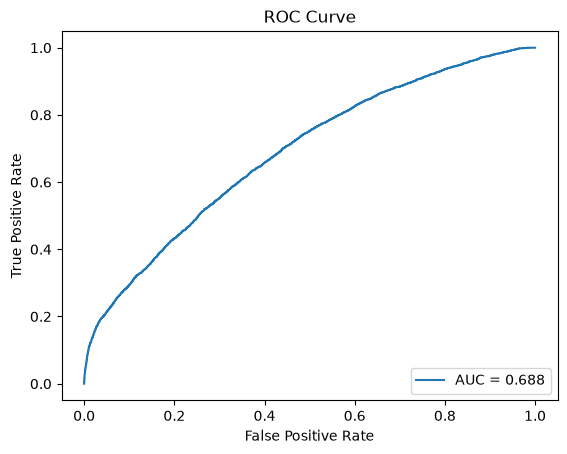

In [8]:
### А для того, чтобы построить и изобразить рок-кривую для SVM, придется
### в начале преобразовать выходы pipe_svm.decision_function

y_score = pipe_svm.decision_function(X_test)
print(y_score)
y_score_min = min(y_score)
y_score_max = max(y_score)

y_prob_svm = np.where(y_score < 0, (y_score - y_score_min) / abs(y_score_min) * 0.5, 0.5 + y_score / y_score_max * 0.5)

# В функцию roc_curve можно передавать как y_score, так и y_prob. То есть преобразовывать decision score в вероятности не нужно
# Ей необязательно получать сырой decision score из decision_function
# Главное, чтобы большее значение означало большую склонность к положительному классу и чтобы порядок объектов не изменился
# А наше преобразование из decision score в вероятности было монотонным, поэтому порядок объектов не менялся
# Можно даже убедиться, что от того, дадим ли мы на вход y_score или y_prob, ничего не изменится

fpr, tpr, thresholds = roc_curve(y_test, y_score)

plt.plot(fpr, tpr, label='AUC = ' + str(round(auc(fpr, tpr), 3)))
plt.title('ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.show()

# RocCurveDisplay.from_estimator(pipe_svm, X_test, y_test)

Постройте калибровочные кривые для обеих моделей. Методом from_estimator для svm воспользоваться не получится.

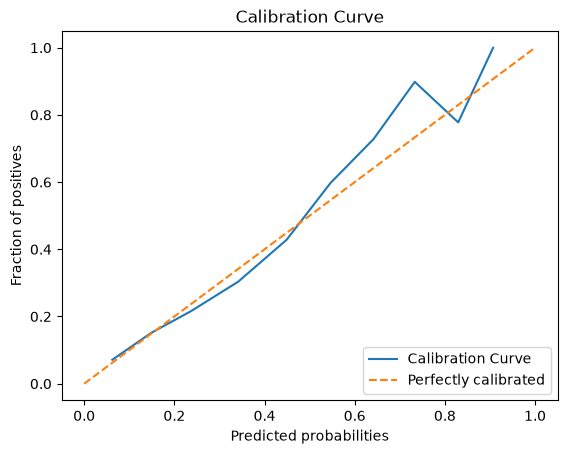

In [9]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay, calibration_curve

#CalibrationDisplay.from_estimator(pipe_lr, X_test, y_test, n_bins=10)

y_prob_lr = pipe_lr.predict_proba(X_test)[:, 1]

prob_true, prob_pred = calibration_curve(y_test, y_prob_lr, n_bins=10)

x = np.linspace(0, 1, 10)
y = np.linspace(0, 1, 10)

plt.plot(prob_pred, prob_true, label='Calibration Curve')
plt.plot(x, y, label='Perfectly calibrated', linestyle='--')
plt.title('Calibration Curve')
plt.xlabel('Predicted probabilities')
plt.ylabel('Fraction of positives')
plt.legend(loc='lower right')


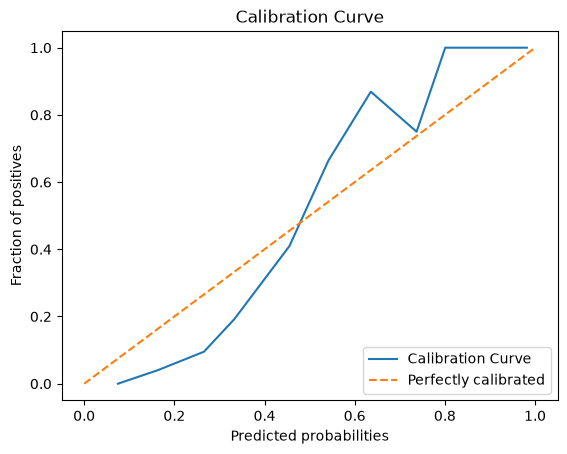

In [10]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Методом from_estimator воспользоваться не получится по той причине, что pipe_svm не имеет метода predict_proba.
# LinearSVC по умолчанию не является вероятностным классификатором:
# Он возвращает decision scores через decision_function, а не вероятности классов.
# Для того, чтобы модель могла предсказывать вероятности, нужно откалибровать выходы модели, то есть её decision_scores

prob_true, prob_pred = calibration_curve(y_test, y_prob_svm, n_bins=10)

x = np.linspace(0, 1, 10)
y = np.linspace(0, 1, 10)

plt.plot(prob_pred, prob_true, label='Calibration Curve')
plt.plot(x, y, label='Perfectly calibrated', linestyle='--')
plt.title('Calibration Curve')
plt.xlabel('Predicted probabilities')
plt.ylabel('Fraction of positives')
plt.legend(loc='lower right')


**Какая калибровочная кривая ближе к диагонали?  Откалибруйте SVM способом как в практике и изобразите новую кривую!

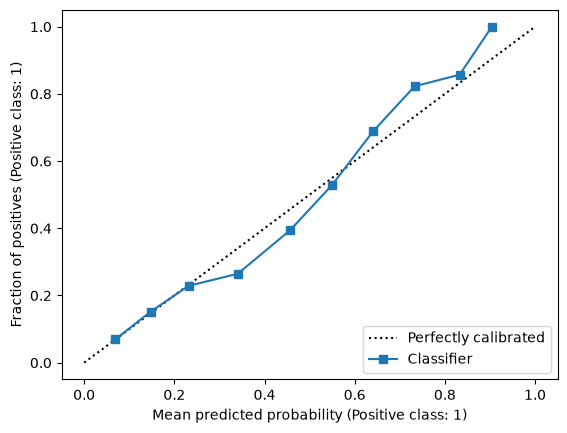

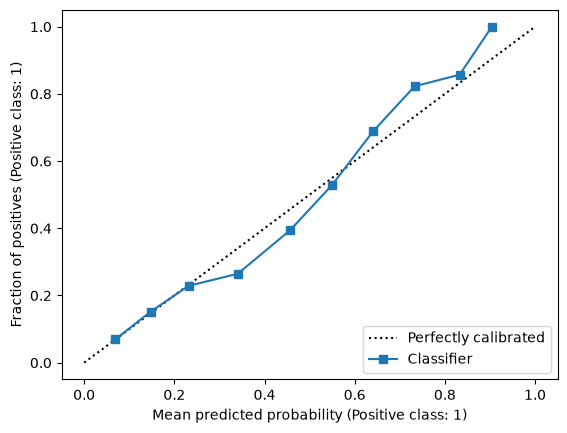

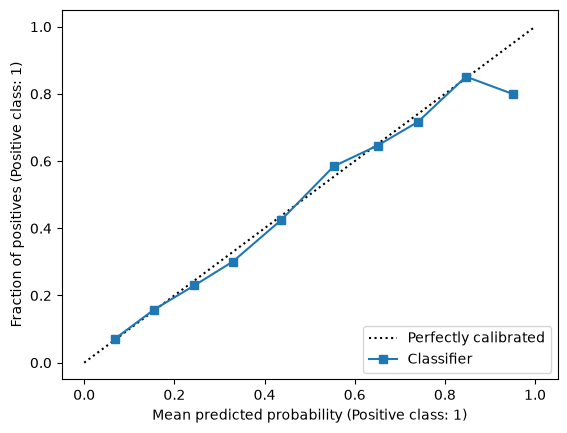

In [11]:
### Калибровка

from sklearn.calibration import CalibratedClassifierCV

# Калибровка методом sigmoid

calibration = CalibratedClassifierCV(pipe_svm, cv=5, method='sigmoid')
calibration.fit(X_train, y_train)

calibrated_probs = calibration.predict_proba(X_test)[:, 1]
calibrated_probs

CalibrationDisplay.from_predictions(y_test, calibrated_probs, n_bins=10).plot()

# Калибровка методом isotonic

calibration = CalibratedClassifierCV(pipe_svm, cv=5, method='isotonic')
calibration.fit(X_train, y_train)

calibrated_probs = calibration.predict_proba(X_test)[:, 1]
calibrated_probs

CalibrationDisplay.from_predictions(y_test, calibrated_probs, n_bins=10)
